## Creation of sessions

In [ ]:
# %load_ext autoreload
# %autoreload 2

In [ ]:
import sys
from pathlib import Path

# If you launched the notebook from the project root (the folder that contains both "tests/" and "fiberphotometry/"),
# then Path.cwd() is already the project root:
project_root = Path.cwd()

# If for some reason your notebook’s working directory is "tests/", you can step up one level:
if not (project_root / "fiberphotometry").exists():
    project_root = project_root.parent

# Now insert that folder into Python’s import search path:
sys.path.insert(0, str(project_root))

# After this, the import should work:
from fiberphotometry.data.data_loading import load_all_sessions
from fiberphotometry.data.session_loading import populate_containers
from fiberphotometry.data.oft_session_loading import populate_oft_containers

In [ ]:
from fiberphotometry.config import PLOTTING_CONFIG
from fiberphotometry.processing.plotting_setup import PlottingSetup

In [ ]:
path = Path("/home/fsp585/Desktop/FiberphotometryCode/src_oft/jonathan_full/Jonathan_IFxDN_csvs")

In [ ]:
sessions = load_all_sessions(
        baseline_dir=str(path),
        session_type="oft",
        remove_bad_signal_sessions=True
        )

In [ ]:
populate_containers(sessions)

In [ ]:
populate_oft_containers(sessions, '/home/fsp585/Desktop/FiberphotometryCode/src_oft/jonathan_full/h5_files', 
                        '/home/fsp585/Desktop/FiberphotometryCode/src_oft/jonathan_full/video_files')

In [ ]:
import pandas as pd
from pathlib import Path
import os
import re

def simplify_filename_details(filename: str) -> str:
    """
    Finds all occurrences of spatial keywords in a filename and joins them.
    It includes 'top' only if it appears in lowercase, to avoid matching
    camera names like 'CenterTopCam'.
    """
    keywords = ['left', 'right', 'bottom', 'top', 'upper', 'lower']
    pattern = r'|'.join(keywords)
    matches = re.finditer(pattern, filename, flags=re.IGNORECASE)
    
    final_words = []
    for match in matches:
        word = match.group(0)
        if word.lower() == 'top':
            if word == 'top':
                final_words.append(word)
        else:
            final_words.append(word)
            
    return '_'.join([w.capitalize() for w in final_words])

# 1. Create a flat list of records
records = []
for s in sessions:
    session_id = f"{s.trial_id}/{s.chamber_id}"
    trial_dir = Path(s.trial_dir)
    
    # A single loop now handles all data types
    for key, df in s.dfs.data.items():
        data_type = "unknown"
        details = "N/A"
        
        if key.startswith('phot_'):
            data_type = "photometry"
            details = "Photometry Data"

        elif key.startswith('tracking_'):
            data_type = "tracking_h5"
            path_col = df.columns[0]
            filename = os.path.basename(df[path_col].iloc[0])
            details = simplify_filename_details(filename)

        elif key.startswith('video_'):
            path_col = df.columns[0]
            filename = os.path.basename(df[path_col].iloc[0])
            # Dynamically get the file extension (e.g., 'avi')
            extension = Path(filename).suffix.lstrip('.')
            data_type = f"video_{extension}"
            details = simplify_filename_details(filename)
        
        elif key.startswith('sync_'):
            data_type = "sync_csv"
            
            # --- THIS BLOCK IS NOW CORRECTED ---
            try:
                # 1. Get the camera name from the new column inside the dataframe
                cam_name = df['camera_name'].iloc[0]
                
                # 2. Now use that correct camera name to find the file path
                path = next(trial_dir.glob(f'{cam_name}_AllTimestampsCombined*.csv'))
                details = simplify_filename_details(path.name)
            except (StopIteration, KeyError, IndexError):
                # Catch errors if column/file is missing or df is empty
                details = "Info not available"
                
        else:
            continue
            
        records.append((session_id, data_type, key, details))

# 2. Convert the list of records into the final DataFrame
summary_df = pd.DataFrame(records, 
                          columns=['Session ID', 'Data Type', 'Source Key', 'Simplified Details'])

# 3. Sort the data for better readability
summary_df = summary_df.sort_values(by=['Session ID', 'Data Type', 'Source Key']).reset_index(drop=True)

# with pd.option_context('display.max_rows', None):
#     display(summary_df)

In [ ]:
for df_name, df in sessions[0].dfs.data.items():
    print(df_name, df.columns)

In [ ]:
PlottingSetup(**PLOTTING_CONFIG['cpt']).apply_plotting_setup_to_sessions(sessions)

In [ ]:
# In your notebook
import pprint # Make sure pprint is imported
from fiberphotometry.data.session_synchronization import synchronize_session_data

print("--- ⏳ Starting synchronization for ALL sessions... ---")

# Loop through every session object in the `sessions` list
for i, s in enumerate(sessions):
    print(f"Processing session {i+1}/{len(sessions)}: {s.trial_id}")
    try:
        # Run the synchronization function on the current session `s`
        synchronize_session_data(s, downsample_video_by=1, tolerance=0.02)
        print(f"✅ Synchronization successful for {s.trial_id}.")
    except Exception as e:
        # Adding a try...except block is good practice in a loop.
        # If one session fails, it won't crash the whole process.
        print(f"❌ ERROR synchronizing session {s.trial_id}: {e}")
    print("-" * 50)

print("\n--- ✅ Synchronization finished for all sessions. ---")

# --- Verification for ALL sessions ---
print("="*50)
print("VERIFICATION OF FINAL DATAFRAME STRUCTURE")
print("="*50)

all_sessions_verified = True
for i, s in enumerate(sessions):
    # Find the synchronized keys for the CURRENT session `s`
    sync_keys = [k for k in s.dfs.data if k.startswith('synchronized_')]
    
    if not sync_keys:
        print(f"❌ Session {i} ({s.trial_id}): FAILED. No synchronized DataFrames found.")
        all_sessions_verified = False
    else:
        print(f"✅ Session {i} ({s.trial_id}): OK. Found {len(sync_keys)} synchronized DataFrame(s).")

if not all_sessions_verified:
    print("\n⚠️ Some sessions failed synchronization. Please review logs above.")
else:
    print("\n--- All sessions were successfully processed. ---")


# --- Detailed structure check of the FIRST session ---
print("\n\n--- Detailed structure check for the first session (sessions[0]) ---")
s0 = sessions[0] # We can safely define s0 here to inspect the first session
sync_keys = sorted([k for k in s0.dfs.data if k.startswith('synchronized_')])

if not sync_keys:
    print("\nNo synchronized DataFrames were found in the first session.")
else:
    for key in sync_keys:
        final_df = s0.dfs.data[key]
        print(f"\n--- Verification for: {key} ---")
        print(f"Total number of rows: {len(final_df)}")
        print("Columns:")
        pprint.pprint(final_df.columns.to_list())

In [ ]:
from fiberphotometry.kpms.syllable_generator import generate_syllable_models
from fiberphotometry.kpms.syllable_appender import extract_and_append_results

print("Successfully imported syllable analysis modules!")

In [ ]:
import keypoint_moseq as kpms

In [ ]:
# # params
curr_frac = 1
latent_dim = 9
n_jax_batches = 24

# --- Define parameters for the FULL run ---
PROJECT_DIR_FULL = f"./kpms_all_sessions_frac_{curr_frac}_ld{latent_dim}_jn{n_jax_batches}"  # Using a new directory for the full analysis
KAPPA = 1.205e+06

# # --- Run the model generation process on ALL sessions ---
# print("--- 🚀 STARTING SYLLABLE MODEL GENERATION (FULL RUN) ---")

# # Capture all three return values from the function
# model_names, original_lengths, video_frame_indexes, final_metadata = generate_syllable_models(
#     sessions=sessions,
#     project_dir=PROJECT_DIR_FULL, # Use the new directory
#     kappa=KAPPA,
#     subset_fraction=curr_frac,
#     num_models=5,               # You can increase this for a more robust model (e.g., 3)
#     ar_iters=50,
#     fitting_iters=200,
#     n_jax_batches=n_jax_batches,
#     latent_dim=latent_dim,
#     test_mode=False             # <-- Set to False to process all files
# )

# print(f"\n--- ✅ FULL MODEL GENERATION FINISHED. {len(model_names)} model(s) created. ---")

In [ ]:
from trimming import create_trimmed_coords_and_confs

In [ ]:
# --- Step 1 & 2: Setup and H5 Path finding (no changes needed) ---
project_path = Path(PROJECT_DIR_FULL)
if not project_path.exists():
    kpms.setup_project(PROJECT_DIR_FULL)
config = kpms.load_config(PROJECT_DIR_FULL)

all_h5_paths = []
for session in sessions:
    session.kpms_h5_path = None
    for df_name, df in session.dfs.data.items():
        if (df_name.startswith('tracking_') and 'h5_path' in df.columns and
            not df['h5_path'].empty and pd.notna(df['h5_path'].iloc[0]) and
            'Center' in df['h5_path'].iloc[0]):
            session.kpms_h5_path = df['h5_path'].iloc[0]
            all_h5_paths.append(session.kpms_h5_path)
            break

# --- Step 3: Load and preprocess data (Consolidated Logic) ---
coordinates, confidences, _ = kpms.load_keypoints(all_h5_paths, 'deeplabcut')

# Get ground-truth info from the FULL data
original_lengths = {key: len(arr) for key, arr in coordinates.items()}
trimmed_coords, trimmed_confs, _, full_video_frame_indexes = create_trimmed_coords_and_confs(
    coordinates, confidences, errors=None
)

# Prepare the data for fitting, calling the new helper function
coords_for_fitting = trimmed_coords
confs_for_fitting = trimmed_confs
video_indexes_for_fitting = full_video_frame_indexes


# Format the data for the model
data, metadata = kpms.format_data(coords_for_fitting, confs_for_fitting, **config)

In [ ]:
import numpy as np

In [ ]:
model_names = [f'final_model_1.20e+06_idx{i}' for i in range(5)]

In [ ]:
# remember to rename to video_frame_indexes
for model_name in model_names:
    print(f"--- 📎 Appending and aligning results for model: {model_name} ---")
    extract_and_append_results(
        sessions=sessions,
        project_dir=PROJECT_DIR_FULL,
        model_name=model_name,
        video_frame_indexes=video_frame_indexes,
        original_lengths=original_lengths,
        metadata=final_metadata
    )

In [ ]:
# --- 🔎 VERIFY RESULTS ---
print("\n--- Verifying that syllable data was appended to sessions ---")

# The default key where results are stored
data_key = 'all_results' 

for session in sessions:
    # Check if the new attribute was successfully added
    if hasattr(session, data_key):
        # Access the dictionary of results
        results_dict = getattr(session, data_key)
        
        # Check if the 'syllable' array exists and print its shape
        if 'syllable' in results_dict:
            syllable_shape = results_dict['syllable'].shape
            print(f"✅ Success! Session {session.trial_id} now has '{data_key}' with syllable data shape: {syllable_shape}")
        else:
            print(f"⚠️ Warning: Session {session.trial_id} has '{data_key}' but is missing the 'syllable' key.")
    else:
        print(f"❌ Error: Session {session.trial_id} is missing the '{data_key}' attribute.")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("--- 📊 Generating data availability plots for all processed sessions ---")

# --- Loop through every session ---
plots_generated = 0
for s in sessions:
    # Check if the current session has the `all_results` attribute
    if hasattr(s, 'all_results'):
        
        # --- Create and display the plot for this specific session ---
        print(f"\nPlotting for session with trial_id: {s.trial_id}")
        
        results_dict = s.all_results
        syllable_array = results_dict['syllable']
        data_exists_mask = ~np.isnan(syllable_array)
        
        fig, ax = plt.subplots(figsize=(18, 4))
        ax.plot(data_exists_mask, color='#007acc', linewidth=1.5)
        
        # Use the current session's ID in the title
        ax.set_title(f"Data Availability for Session {s.trial_id}", fontsize=16)
        ax.set_xlabel("Frame Number (Full Original Timeline)", fontsize=12)
        ax.set_ylabel("Data Status", fontsize=12)
        ax.set_yticks([0, 1])
        ax.set_yticklabels(['NaN (Gap)', 'Valid Data'])
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.set_ylim(-0.1, 1.1)
        
        plt.tight_layout()
        plt.show() # Display the plot for this session before creating the next one
        
        plots_generated += 1

# --- Final Summary ---
if plots_generated == 0:
    print("\n❌ No processed sessions with 'all_results' found in memory to plot.")
else:
    print(f"\n--- ✅ Plot generation complete. {plots_generated} plots created. ---")

In [ ]:
import pickle

# 1. Bundle all the "juice" (essential, slow-to-generate variables) into one dictionary.
#    This ensures you don't lose the outputs of your long computation.
print("--- Bundling essential variables for saving... ---")
state_to_save = {
    'sessions': sessions,
    'model_names': model_names,
    'video_frame_indexes': video_indexes_for_fitting,
    'original_lengths': original_lengths,
    'project_dir_full': PROJECT_DIR_FULL, # Saving for reference
    'kappa': KAPPA                      # Saving for reference
}
print("✅ Bundle complete.")

# 2. Define a new, more descriptive filename for the complete state.
save_filename = f'full_analysis_state_full_data_1_200_iters.pkl'

# 3. Save the entire dictionary to the file.
print(f"\n--- 💾 Saving the complete analysis state to '{save_filename}'... ---")
with open(save_filename, 'wb') as f:
    # We are now saving the 'state_to_save' dictionary, which contains everything.
    pickle.dump(state_to_save, f)

print(f"--- ✅ Save complete. All important data is now in '{save_filename}'. ---")

## Loading of sessions

### Imports and session loading

In [1]:
# --- IMPORTS & SETUP ---

# Enable autoreload (optional but good practice)
# %load_ext autoreload
# %autoreload 2

# Standard library & path setup
import sys
from pathlib import Path

# Data handling and analysis
import pandas as pd
import numpy as np
import pickle
import re

# Visualization
import matplotlib.pyplot as plt
import pprint

# Modeling pipeline
import keypoint_moseq as kpms
import jax

# --- 1. SETUP PROJECT PATH ---
print("Setting up project path...")
project_root = Path.cwd()
if not (project_root / "fiberphotometry").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
print(f"Project root added to path: {project_root}")

# --- 2. IMPORT CUSTOM MODULES ---
print("\nImporting custom project modules...")
try:
    # core Session class and loader
    from fiberphotometry.data.data_loading import Session, load_all_sessions

    # container for holding session data
    from fiberphotometry.data.session_loading import DataContainer

    # OFT-specific session population
    from fiberphotometry.data.oft_session_loading import populate_oft_containers

    # synchronizing different data streams in a session
    from fiberphotometry.data.session_synchronization import synchronize_session_data

    # KPMS pipeline stages
    from fiberphotometry.kpms.syllable_generator import generate_syllable_models
    from fiberphotometry.kpms.syllable_appender import extract_and_append_results
    from fiberphotometry.kpms.trimming import create_trimmed_coords_and_confs
    from fiberphotometry.kpms.batching import create_batches

    print("✅ All custom modules imported successfully.")
except ImportError as e:
    print(f"❌ Failed to import a custom module: {e}")
    print("   Please ensure your notebook is in the correct project directory.")


Setting up project path...
Project root added to path: /home/fsp585/Desktop/FiberphotometryCode

Importing custom project modules...
✅ All custom modules imported successfully.


In [2]:
import pickle
import pandas as pd
import numpy as np

# 1. This filename must exactly match the new file where you saved the dictionary.
#load_filename = f'full_analysis_state_full_data_{curr_frac}.pkl'
# load_filename = 'full_analysis_state_full_data_1.pkl'
load_filename = 'full_analysis_state_full_data_1_200_iters.pkl'
print(f"--- 🚀 Loading complete analysis state from '{load_filename}'... ---")

try:
    # Use 'with open' to safely open the file.
    with open(load_filename, 'rb') as f:
        # 2. Load the entire dictionary object that you saved.
        loaded_state = pickle.load(f)

    # 3. Unpack all the variables from the dictionary back into your notebook's workspace.
    sessions = loaded_state['sessions']
    model_names = loaded_state['model_names']
    video_frame_indexes = loaded_state['video_frame_indexes']
    original_lengths = loaded_state['original_lengths']
    PROJECT_DIR_FULL = loaded_state['project_dir_full']
    KAPPA = loaded_state['kappa']

    print(f"--- ✅ Load complete. Unpacked data for {len(sessions)} sessions into memory. ---")

    # 4. A more comprehensive verification to ensure everything loaded correctly.
    if 'sessions' in locals() and 'model_names' in locals() and 'video_frame_indexes' in locals():
         print("\n✅ Verification successful: 'sessions', 'model_names', and other key variables are loaded.")
         print("You can now proceed directly to your analysis and plotting cells.")
    else:
        print("\n⚠️ Verification failed. Some key variables are missing from the loaded data.")

except FileNotFoundError:
    print(f"\n❌ ERROR: The file '{load_filename}' was not found. Make sure it's in the same directory as your notebook.")
except KeyError as e:
    print(f"\n❌ ERROR: A key was missing from the loaded dictionary: {e}. The save file might be from an older version of your code.")

--- 🚀 Loading complete analysis state from 'full_analysis_state_full_data_1_200_iters.pkl'... ---
--- ✅ Load complete. Unpacked data for 16 sessions into memory. ---

✅ Verification successful: 'sessions', 'model_names', and other key variables are loaded.
You can now proceed directly to your analysis and plotting cells.


### Sanity checks

### Syllable syncing

In [3]:
import pandas as pd

print("--- 🧠 Merging syllable data into synchronized DataFrames ---")

sessions_merged = 0
for i, s in enumerate(sessions):
    try:
        print(f"Processing session {i+1}/{len(sessions)}: {s.trial_id}")
        
        # --- 1. Check if the required data exists ---
        if not hasattr(s, 'all_results'):
            raise KeyError("Attribute 'all_results' not found on this session object.")
        if 'synchronized_data_tracking_0' not in s.dfs.data:
            raise KeyError("DataFrame 'synchronized_data_tracking_0' not found in s.dfs.data.")

        # --- 2. Get the target DataFrame and source data ---
        target_df = s.dfs.data['synchronized_data_tracking_0']
        syllable_array = s.all_results['syllable']

        # --- 3. Perform the length check as you requested ---
        if len(target_df) != len(syllable_array):
            # If lengths don't match, raise an error to be caught by the 'except' block
            raise ValueError(f"Length mismatch! DataFrame has {len(target_df)} rows, but syllable array has {len(syllable_array)} elements.")

        # --- 4. If checks pass, add the new column ---
        # This modifies the DataFrame directly within your session object
        target_df['syllable'] = syllable_array
        print(f"✅ Successfully added 'syllable' column.")
        sessions_merged += 1

    except (KeyError, ValueError) as e:
        # This will catch any errors raised above and print a warning,
        # allowing the loop to continue with the next session.
        print(f"❌ SKIPPING session {s.trial_id}: {e}")
    
    print("-" * 50)

print(f"\n--- ✅ Merge complete. {sessions_merged} out of {len(sessions)} sessions were updated. ---")


# --- Final Verification ---
# Let's check the first session to see if the new column is there.
print("\n--- 🔍 Final Verification of the first session ---")
if 'sessions' in locals() and 'syllable' in sessions[0].dfs.data['synchronized_data_tracking_0'].columns:
    print("Verification successful: 'syllable' column is present.")
    # Display the first few rows of the updated DataFrame
    #display(sessions[0].dfs.data['synchronized_data_tracking_0'].head())
else:
    print("Verification failed: 'syllable' column not found in the first session's DataFrame.")

--- 🧠 Merging syllable data into synchronized DataFrames ---
Processing session 1/16: T1_1658.740.1666.e
✅ Successfully added 'syllable' column.
--------------------------------------------------
Processing session 2/16: T1_1658.740.1666.e
✅ Successfully added 'syllable' column.
--------------------------------------------------
Processing session 3/16: T1_1658.740.1666.e
✅ Successfully added 'syllable' column.
--------------------------------------------------
Processing session 4/16: T2_1664.1678.e.e
✅ Successfully added 'syllable' column.
--------------------------------------------------
Processing session 5/16: T2_1664.1678.e.e
✅ Successfully added 'syllable' column.
--------------------------------------------------
Processing session 6/16: T3_1694.1680.728.e
✅ Successfully added 'syllable' column.
--------------------------------------------------
Processing session 7/16: T3_1694.1680.728.e
✅ Successfully added 'syllable' column.
-------------------------------------------------

### Model loading and more sanity checks

In [4]:
PROJECT_DIR = "./kpms_all_sessions_frac_1_ld9_jn24"  # Using a new directory for the full analysis
MODEL_NAME = 'final_model_1.20e+06_idx1'

In [5]:
# # define your ten model names
# model_names = [f'final_model_1.20e+06_idx{i}' for i in range(5)]

# # compute EML scores and their standard errors
# eml_scores, eml_std_errs = kpms.expected_marginal_likelihoods(PROJECT_DIR, model_names)

# # pick the best model
# best_model_name = model_names[np.argmax(eml_scores)]
# print(f"Best model: {best_model_name}")

# # visualize the EML scores across the ensemble
# kpms.plot_eml_scores(eml_scores, eml_std_errs, model_names)


In [6]:
import keypoint_moseq as kpms
model, data, metadata, current_iter = kpms.load_checkpoint(PROJECT_DIR, MODEL_NAME)
results = kpms.extract_results(model, metadata, PROJECT_DIR, MODEL_NAME, save_results=False)

In [7]:
# model_names = [f'final_model_1.20e+06_idx{i}' for i in range(5)]

# for model_name in model_names:
#     # load the specific checkpoint
#     model, data, metadata, current_iter = kpms.load_checkpoint(PROJECT_DIR, model_name)
    
#     # extract results for this model
#     results = kpms.extract_results(model, metadata, PROJECT_DIR, model_name, save_results=True)


In [8]:
config = kpms.load_config(PROJECT_DIR)

In [9]:
import os
import h5py
import numpy as np
import jax.numpy as jnp
from jax_moseq.utils import unbatch
from jax_moseq.models.keypoint_slds import estimate_coordinates

# compute the estimated coordinates
Y_est = estimate_coordinates(
    jnp.array(model['states']['x']),
    jnp.array(model['states']['v']),
    jnp.array(model['states']['h']),
    jnp.array(model['params']['Cd'])
)

# generate a dictionary with reconstructed coordinates for each recording
coordinates_est = unbatch(Y_est, *metadata)

In [10]:
coordinates_est['Arena1234_CenterTopCamVid_2024-12-13T12_20_06_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020'].shape

(231374, 17, 2)

In [11]:
for k, v in model['states'].items():
    print(k, v.shape)

h (367, 10030)
s (367, 10030, 17)
v (367, 10030, 2)
x (367, 10030, 9)
z (367, 10027)


In [12]:
for k, v in model['params'].items():
    print(k, v.shape)

Ab (100, 9, 28)
Cd (32, 10)
Q (100, 9, 9)
betas (100,)
pi (100, 100)
sigmasq (17,)


In [13]:
for k, v in config.items():
    # try .shape first; getattr(v, 'shape', None) will be None if no .shape
    shape = getattr(v, 'shape', None)
    if shape is None:
        try:
            # if it has a __len__, len(v) will work
            shape = len(v)
        except TypeError:
            # neither .shape nor len → skip
            continue
    print(k, shape)


bodyparts 27
use_bodyparts 17
skeleton 20
anterior_bodyparts 1
posterior_bodyparts 1
error_estimator 2
obs_hypparams 4
ar_hypparams 4
trans_hypparams 4
cen_hypparams 1
recording_name_suffix 0
video_dir 61
keypoint_colormap 6
anterior_idxs (1,)
posterior_idxs (1,)


In [14]:
for k, v in coordinates_est.items():
    print(k, v.shape)

Arena1234_CenterTopCamVid_2024-12-16T12_42_27_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020 (219502, 17, 2)
Arena1234_CenterTopCamVid_2024-12-13T13_37_45_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part2 (31809, 17, 2)
Arena1234_CenterTopCamVid_2024-12-16T14_05_53_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020 (223005, 17, 2)
Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part1 (29113, 17, 2)
Arena1234_CenterTopCamVid_2024-12-13T14_50_39_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020 (221549, 17, 2)
Arena1234_CenterTopCamVid_2024-12-13T12_20_06_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020 (231374, 17, 2)
Arena1234_CenterTopCamVid_2024-12-16T11_27_19_bottom_rightDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020 (218219, 17, 2)
Arena1234_CenterTopCamVid_2024-1

### Trajectory plots

In [18]:
#perm = kpms.reindex_syllables_in_checkpoint(PROJECT_DIR, MODEL_NAME)

config['bodyparts'] = config['use_bodyparts']
#kpms.generate_trajectory_plots(coordinates_est, results, PROJECT_DIR, MODEL_NAME, fps=60, min_frequency=0.000, min_duration=1, **config)

### Grid movie preprocessing and generation

In [19]:
import os
import pprint # Make sure pprint is imported for nice printing

def map_syllable_parts_to_videos(video_frame_indexes: dict, video_dir: str) -> dict:
    """
    Maps syllable part keys (e.g., '..._part1') to their corresponding video paths.

    This function is designed to work after keypoint-MoSeq splits a single
    recording into multiple parts during model fitting. It ensures that every key
    in the video_frame_indexes dictionary is mapped to the correct video file.

    Args:
        video_frame_indexes: The dictionary returned by the syllable generation step,
                             where keys may have '_partX' suffixes.
        video_dir: The path to the directory containing the video files.

    Returns:
        A dictionary where keys are the syllable part keys and values are the
        full paths to the single corresponding video file.
    """
    video_extensions = ('.mp4', '.avi', '.mov', '.mkv')
    video_files = [f for f in os.listdir(video_dir) if f.lower().endswith(video_extensions)]
    
    video_path_map = {}
    
    # Iterate through the keys of the video_frame_indexes dictionary
    for part_key in video_frame_indexes.keys():
        
        # Find the original H5 base name by stripping any '_partX' suffix.
        # We split the string at '_part' and take the first piece.
        h5_base_name = part_key.split('_part')[0]
        
        try:
            # Use the same logic as before to find the video's root name from the H5 base name
            video_root = h5_base_name.split('DLC_')[0]

            # Find the matching video file in the video directory
            found_match = False
            for video_file in video_files:
                if video_file.startswith(video_root):
                    # CRITICAL: Map the *original part_key* to the found video path.
                    # This ensures every part maps back to the same, single video file.
                    video_path_map[part_key] = os.path.join(video_dir, video_file)
                    found_match = True
                    break # Match found, move to the next part_key
            
            if not found_match:
                 print(f"Warning: No matching video found for key: {part_key}")

        except IndexError:
            print(f"Warning: Could not parse '{part_key}'. 'DLC_' delimiter not found. Skipping.")

    return video_path_map

In [20]:
# --- Define the paths to your directories ---
VIDEO_DIRECTORY = '/home/fsp585/Desktop/FiberphotometryCode/src_oft/jonathan_full/video_files'

# --- Call the NEW function to get the correct mapping ---
# It uses the keys from video_frame_indexes as the source of truth.
h5_to_video_map_corrected = map_syllable_parts_to_videos(
    video_frame_indexes=video_frame_indexes,
    video_dir=VIDEO_DIRECTORY
)

# --- Print the results nicely to verify ---
print("--- Corrected File Mapping Results ---")
pprint.pprint(h5_to_video_map_corrected)

--- Corrected File Mapping Results ---
{'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part1': '/home/fsp585/Desktop/FiberphotometryCode/src_oft/jonathan_full/video_files/Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_left.avi',
 'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part2': '/home/fsp585/Desktop/FiberphotometryCode/src_oft/jonathan_full/video_files/Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_left.avi',
 'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part3': '/home/fsp585/Desktop/FiberphotometryCode/src_oft/jonathan_full/video_files/Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_left.avi',
 'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_rightDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020': '/home/fsp585/Desk

In [21]:
centroids, headings = kpms.get_centroids_headings(coordinates_est, **config)

In [22]:
video_frame_indexes

{'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part1': array([69521, 69522, 69523, ..., 98631, 98632, 98633]),
 'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part2': array([100461, 100462, 100463, ..., 199772, 199773, 199774]),
 'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part3': array([200702, 200703, 200704, ..., 292747, 292748, 292749]),
 'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_rightDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020': array([ 92167,  92168,  92169, ..., 310627, 310628, 310629]),
 'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020': array([ 39631,  39632,  39633, ..., 271002, 271003, 271004]),
 'Arena1234_CenterTopCamVid_2024-12-13T13_37_45_bo

In [ ]:
# --- 1. Align Dictionaries to a Common Set of Keys ---
# The AssertionError indicates a mismatch between the keys in `results` (from the model)
# and `video_frame_indexes` (from the syllable generation step).
# We will create temporary versions of all input dicts containing only the keys they share.

print("--- Aligning input dictionaries to a common set of keys... ---")

# Find the set of keys that exist in BOTH `results` and `video_frame_indexes_30fps`.
keys_results = set(results.keys())
keys_frames = set(video_frame_indexes.keys())
common_keys = keys_results.intersection(keys_frames)

print(f"Original `results` keys: {len(keys_results)}")
print(f"Original `video_frame_indexes` keys: {len(keys_frames)}")
print(f"Found {len(common_keys)} common keys to use for movie generation.")

# For debugging, show the differences (optional, can be commented out)
if len(keys_results) != len(common_keys) or len(keys_frames) != len(common_keys):
    print("\nKeys in results ONLY:", keys_results - keys_frames)
    print("Keys in frames ONLY:", keys_frames - keys_results)
    print("-" * 20)

# Create new, temporary dictionaries filtered to only contain the common keys.
results_common = {k: results[k] for k in common_keys}
video_frame_indexes_common = {k: video_frame_indexes[k] for k in common_keys}
h5_to_video_map_common = {k: h5_to_video_map_corrected[k] for k in common_keys if k in h5_to_video_map_corrected}
coordinates_common = {k: coordinates_est[k] for k in common_keys if k in coordinates_est}
centroids_common = {k: centroids[k] for k in common_keys if k in centroids}
headings_common = {k: headings[k] for k in common_keys if k in headings}


# --- 2. Create a temporary copy of the config to avoid the 'fps' conflict ---
config_for_movies = config.copy()
if 'fps' in config_for_movies:
    del config_for_movies['fps']


# --- 3. Now, call the function with the ALIGNED and CORRECTED data ---
print("\n--- Generating grid movies with aligned data... ---")
kpms.generate_grid_movies(
    results_common,
    PROJECT_DIR,
    MODEL_NAME,
    video_paths=h5_to_video_map_common,
    coordinates=coordinates_common,
    centroids=centroids_common,
    headings=headings_common,
    fps=60,
    video_frame_indexes=video_frame_indexes_common,
    overlay_keypoints=False,
    **config_for_movies
)

### Group assignment and syllable labeling

In [23]:
import re

# metadata_names is the list/array of all result names (e.g., metadata[0])
metadata_names = metadata[0]

for sess in sessions:
    sess.result_names = []
    h5_path = sess.kpms_h5_path
    for name in metadata_names:
        # strip "_part#" only for matching
        base = re.sub(r'_part\d+$', '', name)
        if base in h5_path and name not in sess.result_names:
            # append the full original name (with part suffix)
            sess.result_names.append(name)

In [24]:
import pandas as pd

# build a list of dicts
rows = []
for sess in sessions:
    for name in sess.result_names:
        rows.append({
            "name": name,
            "group": sess.genotype
        })

# make a DataFrame
index_df = pd.DataFrame(rows)

# (optionally) save it back out so your interactive widget picks it up
index_df.to_csv(os.path.join(PROJECT_DIR, "index.csv"), index=False)

# inspect
print(index_df.head())


                                                name group
0  Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...    KI
1  Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...    WT
2  Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...    WT
3  Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...    WT
4  Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...    KI


In [25]:
moseq_df = kpms.compute_moseq_df(PROJECT_DIR, MODEL_NAME, smooth_heading=True)

In [26]:
moseq_df

,name,centroid_x,centroid_y,heading,angular_velocity,velocity_px_s,syllable,frame_index,group,onset
0,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,169.456559,201.860363,-1.049720,0.000000,0.000000,7,0,WT,True
1,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,169.336399,202.913497,-1.049720,0.022421,31.799003,7,1,WT,False
2,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,168.763701,203.285897,-1.049720,0.036111,20.493858,7,2,WT,False
3,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,168.657766,204.372900,-1.029941,0.035251,32.764602,7,3,WT,False
4,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,169.075141,205.394482,-1.029941,0.018921,33.106615,7,4,WT,False
...,...,...,...,...,...,...,...,...,...,...
3544884,Arena1234_CenterTopCamVid_2024-12-16T15_14_26_...,189.983804,208.697307,-0.223663,1.816051,165.050971,31,220505,KI,True
3544885,Arena1234_CenterTopCamVid_2024-12-16T15_14_26_...,189.107771,212.139561,-0.208518,1.621323,106.559316,18,220506,KI,True
3544886,Arena1234_CenterTopCamVid_2024-12-16T15_14_26_...,187.884826,215.361772,-0.208231,1.287334,103.394457,18,220507,KI,False
3544887,Arena1234_CenterTopCamVid_2024-12-16T15_14_26_...,185.991553,217.266942,-0.208231,0.875232,80.577537,18,220508,KI,False


In [27]:
stats_df = kpms.compute_stats_df(
    PROJECT_DIR,
    MODEL_NAME,
    moseq_df,
    min_frequency=0.005,  # threshold frequency for including a syllable in the dataframe
    groupby=["group", "name"],  # column(s) to group the dataframe by
    fps=60,
)  # frame rate of the video from which keypoints were inferred

stats_df

,group,name,syllable,heading_mean,heading_std,heading_min,heading_max,angular_velocity_mean,angular_velocity_std,angular_velocity_min,angular_velocity_max,velocity_px_s_mean,velocity_px_s_std,velocity_px_s_min,velocity_px_s_max,frequency,duration
0,KI,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,0,0.253595,1.341934,-3.141415,3.139920,0.130345,4.485103,-188.376403,188.354880,26.873888,17.459970,0.077634,136.814590,0.124412,0.358901
1,KI,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,1,-0.514128,1.740020,-3.140444,3.140683,0.315382,11.664641,-188.072656,3.444294,30.430489,16.944380,0.104072,135.207925,0.073593,0.321867
2,KI,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,2,-0.193747,1.722176,-3.141120,3.138554,-0.140818,5.699769,-188.267193,188.226724,27.641284,17.822967,0.183033,170.810664,0.077922,0.660749
3,KI,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,3,0.078072,1.565949,-3.136166,3.137331,-0.012892,2.666441,-188.051150,2.841535,19.678121,11.205292,0.157701,99.167770,0.061735,0.765041
4,KI,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,4,-0.363733,2.013156,-3.141095,3.141467,-0.300112,12.219155,-188.365004,188.095974,26.575705,16.704696,0.299160,124.506079,0.057218,0.544518
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
791,WT,Arena1234_CenterTopCamVid_2024-12-16T14_05_53_...,33,-1.012373,1.048192,-2.328246,1.234174,-0.057173,0.141455,-0.515813,0.582404,17.499499,9.008736,0.456307,51.589900,0.000937,1.543333
792,WT,Arena1234_CenterTopCamVid_2024-12-16T14_05_53_...,34,-1.437857,0.520430,-2.508247,-0.096890,-0.248608,0.501018,-1.361321,1.241718,19.564224,10.376315,0.778110,48.890711,0.001124,0.475000
793,WT,Arena1234_CenterTopCamVid_2024-12-16T14_05_53_...,35,-0.437014,1.903327,-2.481176,2.802204,0.074455,0.895632,-2.095084,2.179077,20.063095,11.998677,1.833276,65.251564,0.002248,0.169444
794,WT,Arena1234_CenterTopCamVid_2024-12-16T14_05_53_...,36,0.880899,1.917960,-3.141134,3.108300,0.043618,0.293680,-0.428275,0.769581,20.324396,10.579214,1.263642,51.153770,0.001124,0.302778


In [28]:
MODEL_NAME

'final_model_1.20e+06_idx1'

In [30]:
PROJECT_DIR

'./kpms_all_sessions_frac_1_ld9_jn24'

In [29]:
kpms.label_syllables(PROJECT_DIR, MODEL_NAME, moseq_df)

BokehModel(combine_events=True, render_bundle={'docs_json': {'17774f08-3116-45d7-8045-02b22ea93ef0': {'version…

ValueError: failed to validate Video(id='e8282bfd-6420-48f7-8a61-08d86ac05feb', ...).volume: expected a value of type Integral, got None of type NoneType

In [31]:
sessions[0].kpms_h5_path

'/home/fsp585/Desktop/FiberphotometryCode/src_oft/jonathan_full/h5_files/Arena1234_CenterTopCamVid_2024-12-13T12_20_06_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020.h5'

In [ ]:
kpms.interactive_group_setting

### Plotting setup and more checks

In [32]:
from fiberphotometry.config import PLOTTING_CONFIG
from fiberphotometry.processing.plotting_setup import PlottingSetup

In [33]:
PlottingSetup(**PLOTTING_CONFIG['cpt']).apply_plotting_setup_to_sessions(sessions)

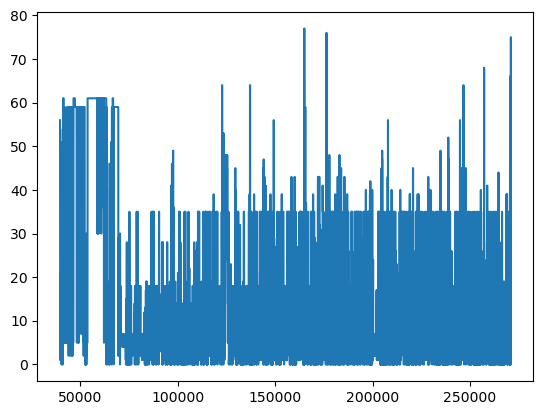

In [34]:
plt.plot(sessions[0].all_results['syllable'])

In [35]:
sessions[0].dfs.data.keys()

dict_keys(['phot_415', 'phot_470', 'sync_0', 'sync_1', 'tracking_0', 'tracking_1', 'video_0', 'video_1', 'synchronized_data_tracking_0', 'synchronized_data_tracking_1'])

In [36]:
sessions[0].dfs.data['synchronized_data_tracking_0']

,FP3002_System_Timestamp,signal_0_470,signal_1_470,signal_0_470_dff,signal_0_470_dff_z,signal_1_470_dff,signal_1_470_dff_z,signal_0_415,signal_1_415,curr_video_frame,current_h5_row,syllable
0,1256.268512,0.005478,0.003945,-0.830494,-1.540178,-0.990481,-1.115997,0.003922,0.003922,0,0,NaN
1,1256.331008,NaN,NaN,NaN,NaN,NaN,NaN,0.003922,0.003922,1,1,NaN
2,1256.331008,NaN,NaN,NaN,NaN,NaN,NaN,0.003922,0.003922,2,2,NaN
3,1256.331008,NaN,NaN,NaN,NaN,NaN,NaN,0.003922,0.003922,3,3,NaN
4,1256.343488,0.005404,0.003953,-0.838581,-1.559944,-0.986974,-1.112305,0.003922,0.003922,4,4,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
319139,5245.381568,0.004032,0.003942,-0.987923,-1.924948,-0.991483,-1.117052,0.003922,0.003922,319139,319139,NaN
319140,5245.394080,0.004032,0.003942,-0.987923,-1.924948,-0.991483,-1.117052,NaN,NaN,319140,319140,NaN
319141,5245.406560,0.004032,0.003942,-0.987923,-1.924948,-0.991483,-1.117052,0.003922,0.003922,319141,319141,NaN
319142,5245.419072,NaN,NaN,NaN,NaN,NaN,NaN,0.003922,0.003922,319142,319142,NaN


In [37]:
sessions[0].dfs.data['phot_470']

,FrameCounter,SystemTimestamp,LedState,ComputerTimestamp,signal_0,signal_1,signal_0_dff,signal_0_dff_z,signal_1_dff,signal_1_dff_z
0,1309,1256.156000,2,4.442315e+07,0.005440,0.003953,-0.834699,-1.550456,-0.986974,-1.112305
1,1313,1256.206016,2,4.442320e+07,0.005466,0.003950,-0.831788,-1.543341,-0.988477,-1.113887
2,1317,1256.256000,2,4.442325e+07,0.005478,0.003945,-0.830494,-1.540178,-0.990481,-1.115997
3,1321,1256.306016,2,4.442330e+07,0.005408,0.003952,-0.838150,-1.558889,-0.987475,-1.112832
4,1325,1256.356000,2,4.442335e+07,0.005404,0.003953,-0.838581,-1.559944,-0.986974,-1.112305
...,...,...,...,...,...,...,...,...,...,...
79781,320433,5245.194080,2,4.841255e+07,0.004049,0.003945,-0.986090,-1.920468,-0.990481,-1.115997
79782,320437,5245.244064,2,4.841260e+07,0.004018,0.003935,-0.989541,-1.928901,-0.994489,-1.120217
79783,320441,5245.294080,2,4.841265e+07,0.004041,0.003953,-0.986953,-1.922576,-0.986974,-1.112305
79784,320445,5245.344064,2,4.841270e+07,0.004047,0.003940,-0.986306,-1.920995,-0.992485,-1.118107


### Syllable based signatures

Syllables to plot: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0, 21.0, 22.0, 23.0, 24.0, 25.0, 26.0, 27.0, 28.0, 29.0, 30.0, 31.0, 32.0, 33.0, 34.0, 35.0, 36.0, 37.0, 38.0, 39.0, 40.0, 41.0, 42.0, 43.0, 44.0, 45.0, 46.0, 47.0, 48.0, 49.0, 50.0, 51.0, 52.0, 53.0, 54.0, 55.0, 56.0, 57.0, 58.0, 59.0, 60.0, 61.0, 62.0, 63.0, 64.0, 65.0, 66.0, 67.0, 68.0, 69.0, 70.0, 71.0, 72.0, 73.0, 74.0, 75.0, 76.0, 77.0, 78.0, 79.0, 80.0, 81.0, 82.0, 83.0, 84.0, 85.0, 86.0, 87.0, 88.0, 89.0, 90.0, 91.0, 92.0, 93.0, 94.0, 95.0, 96.0, 97.0, 98.0, 99.0]
Skipped 28 KI traces for syllable 0.0, region VS, hemisphere left due to NaNs
Skipped 28 KI traces for syllable 0.0, region DMS, hemisphere right due to NaNs


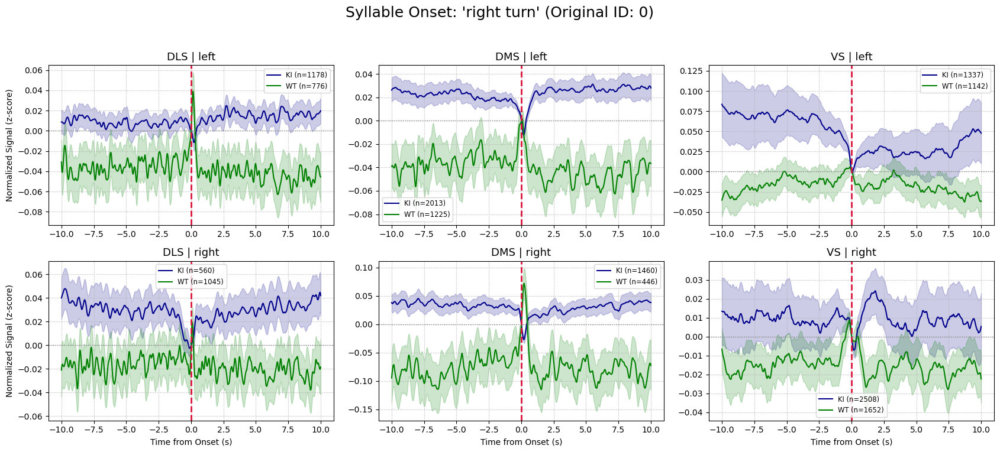

Skipped 21 KI traces for syllable 1.0, region VS, hemisphere left due to NaNs
Skipped 21 KI traces for syllable 1.0, region DMS, hemisphere right due to NaNs


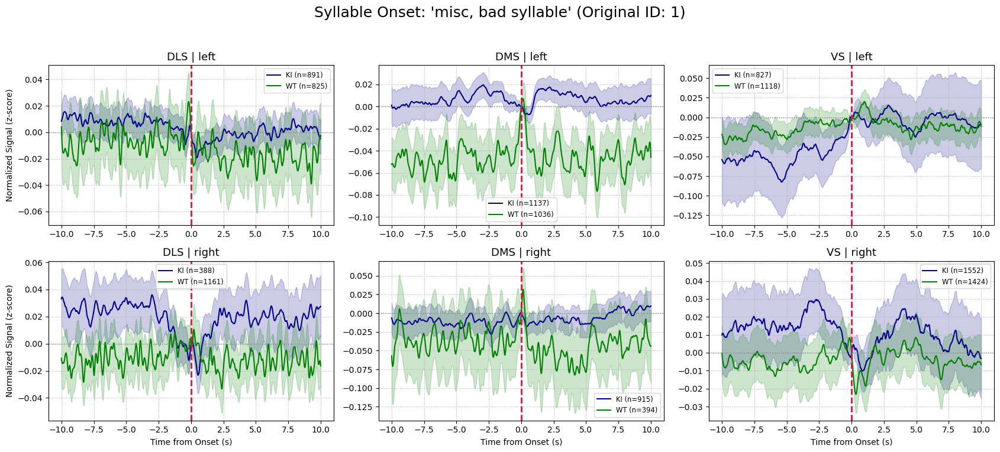

Skipped 6 KI traces for syllable 2.0, region VS, hemisphere left due to NaNs
Skipped 6 KI traces for syllable 2.0, region DMS, hemisphere right due to NaNs


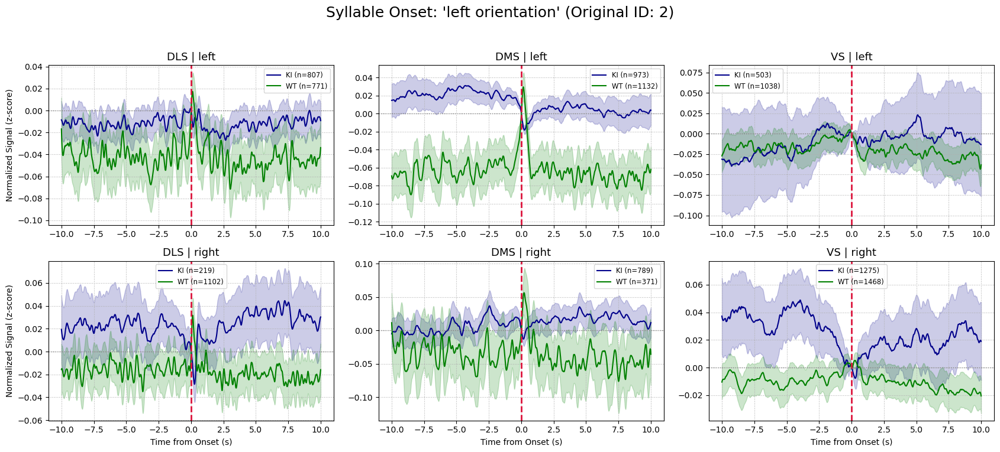

Skipped 21 KI traces for syllable 3.0, region VS, hemisphere left due to NaNs
Skipped 21 KI traces for syllable 3.0, region DMS, hemisphere right due to NaNs


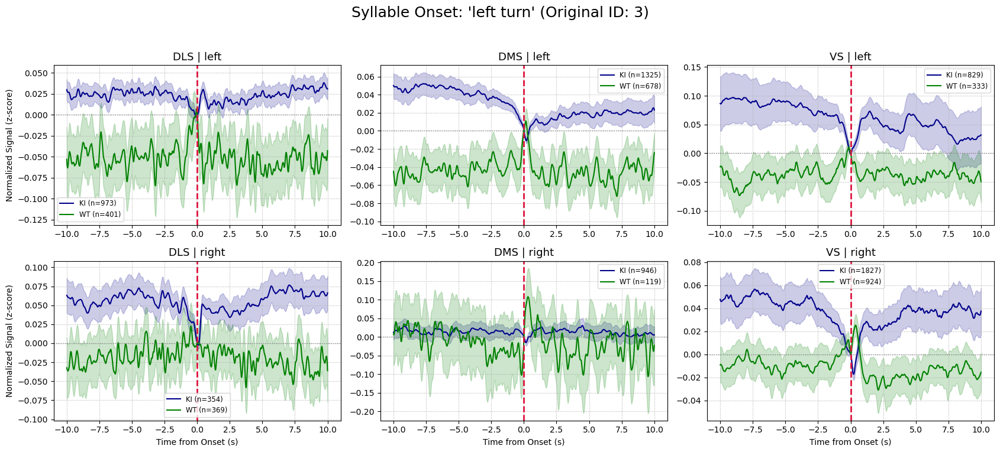

Skipped 8 KI traces for syllable 4.0, region VS, hemisphere left due to NaNs
Skipped 8 KI traces for syllable 4.0, region DMS, hemisphere right due to NaNs


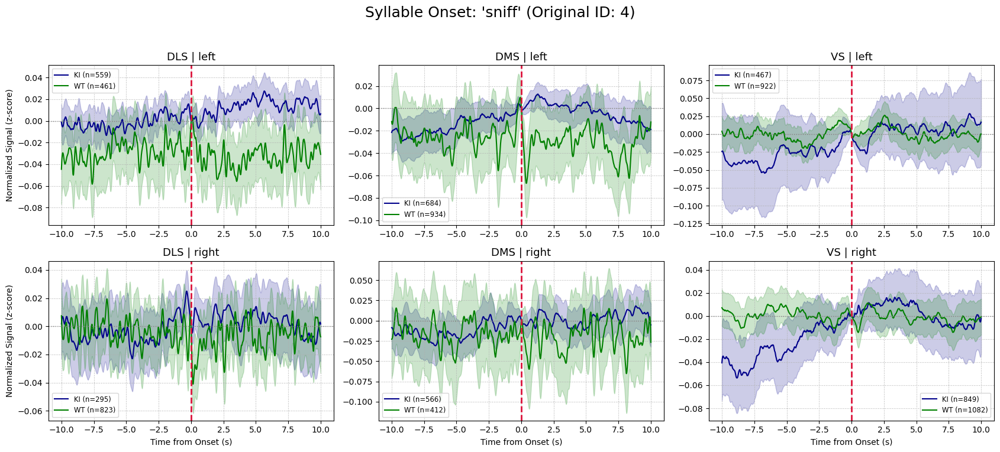

Skipped 3 KI traces for syllable 5.0, region VS, hemisphere left due to NaNs
Skipped 3 KI traces for syllable 5.0, region DMS, hemisphere right due to NaNs


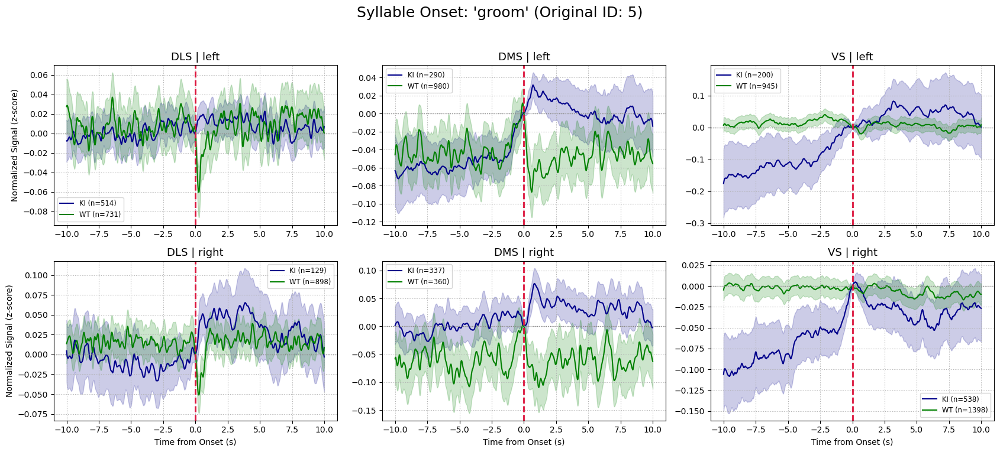

Skipped 4 KI traces for syllable 6.0, region VS, hemisphere left due to NaNs
Skipped 4 KI traces for syllable 6.0, region DMS, hemisphere right due to NaNs


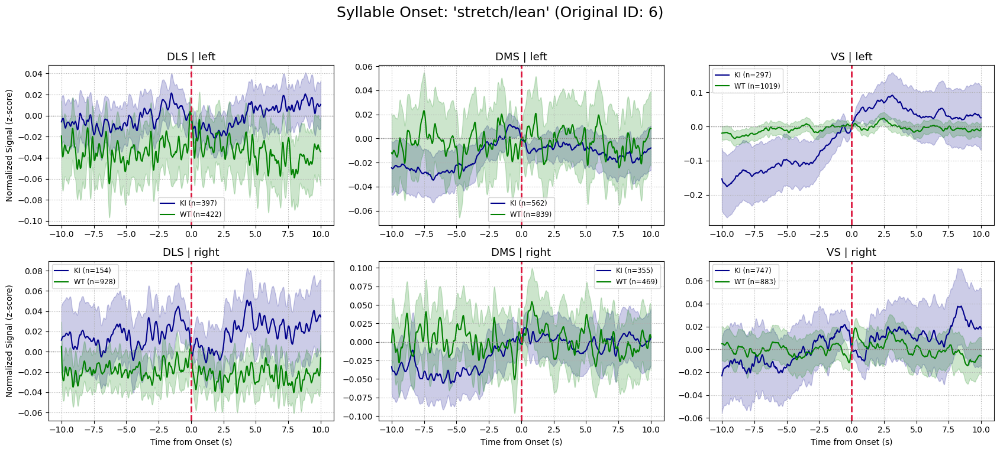

Skipped 5 KI traces for syllable 7.0, region VS, hemisphere left due to NaNs
Skipped 5 KI traces for syllable 7.0, region DMS, hemisphere right due to NaNs


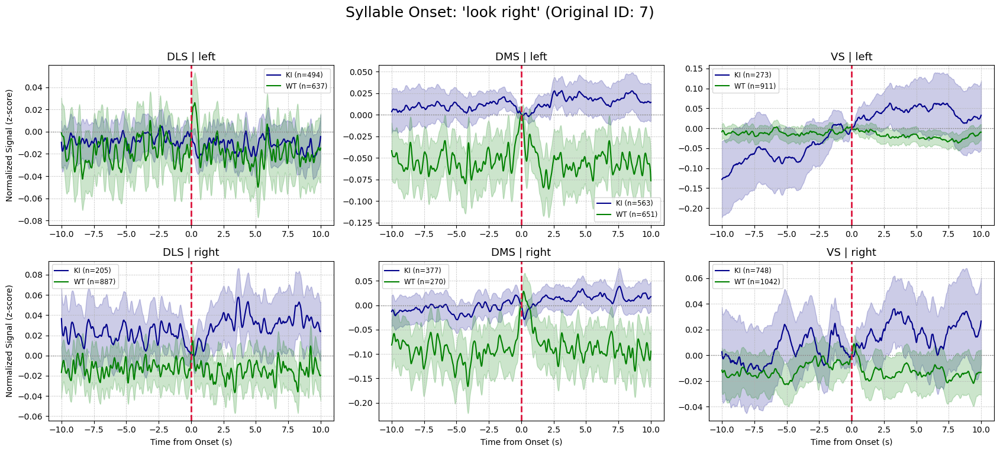

Skipped 22 KI traces for syllable 8.0, region VS, hemisphere left due to NaNs
Skipped 22 KI traces for syllable 8.0, region DMS, hemisphere right due to NaNs


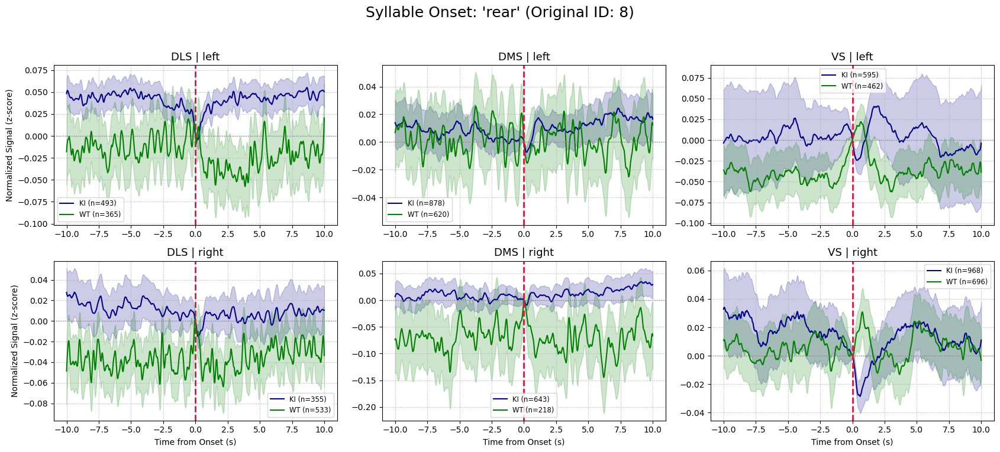

Skipped 21 KI traces for syllable 9.0, region VS, hemisphere left due to NaNs
Skipped 21 KI traces for syllable 9.0, region DMS, hemisphere right due to NaNs


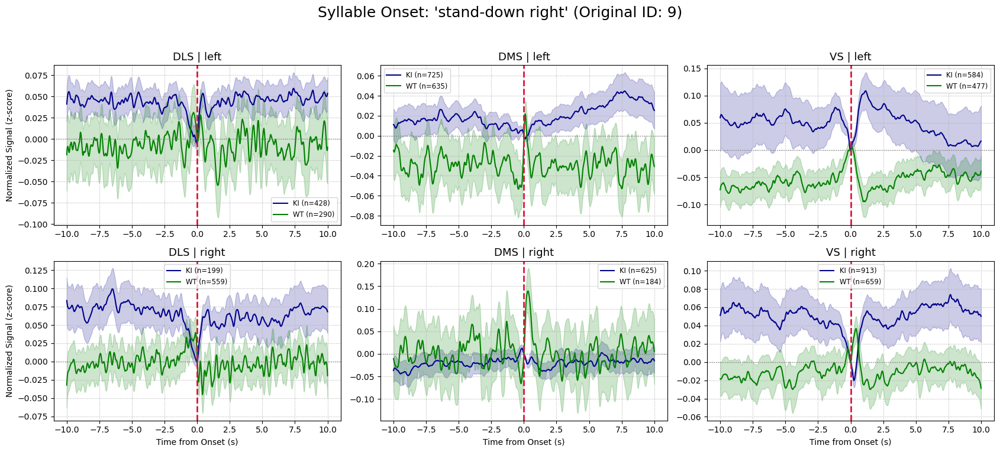

Skipped 16 KI traces for syllable 10.0, region VS, hemisphere left due to NaNs
Skipped 16 KI traces for syllable 10.0, region DMS, hemisphere right due to NaNs


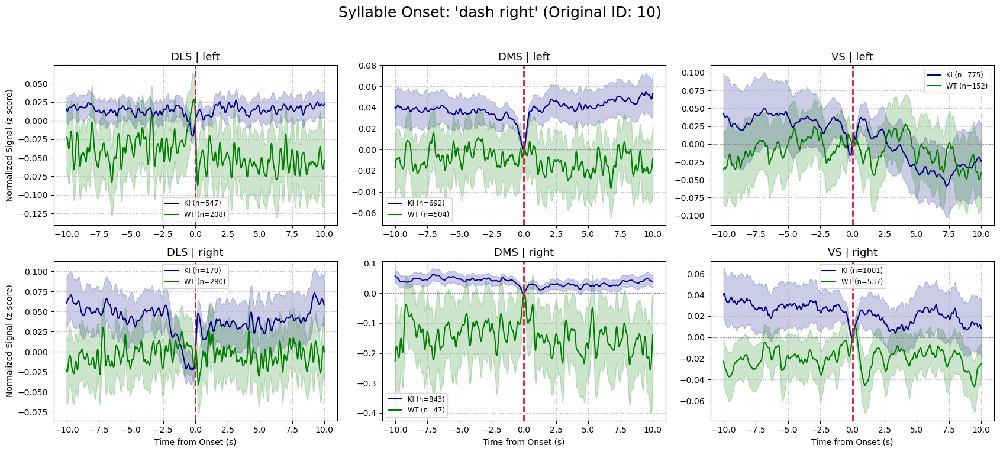

Skipped 14 KI traces for syllable 11.0, region VS, hemisphere left due to NaNs
Skipped 14 KI traces for syllable 11.0, region DMS, hemisphere right due to NaNs


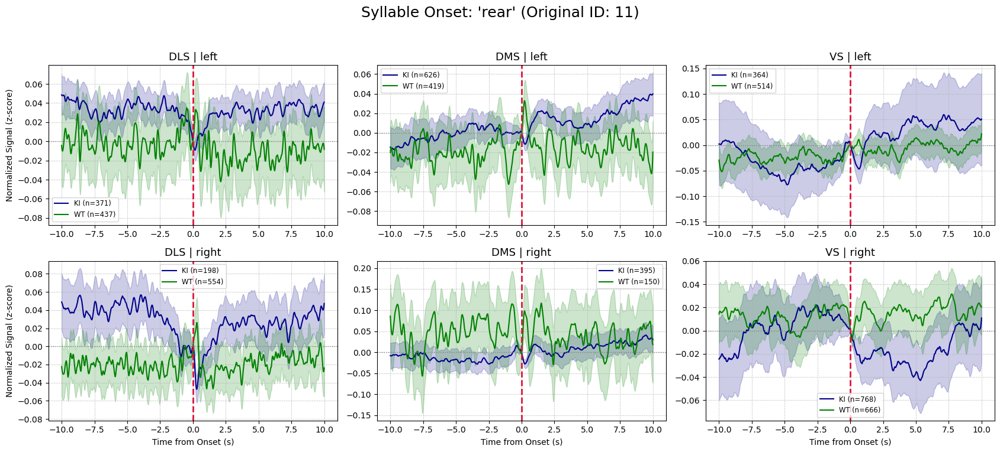

Skipped 19 KI traces for syllable 12.0, region VS, hemisphere left due to NaNs
Skipped 19 KI traces for syllable 12.0, region DMS, hemisphere right due to NaNs


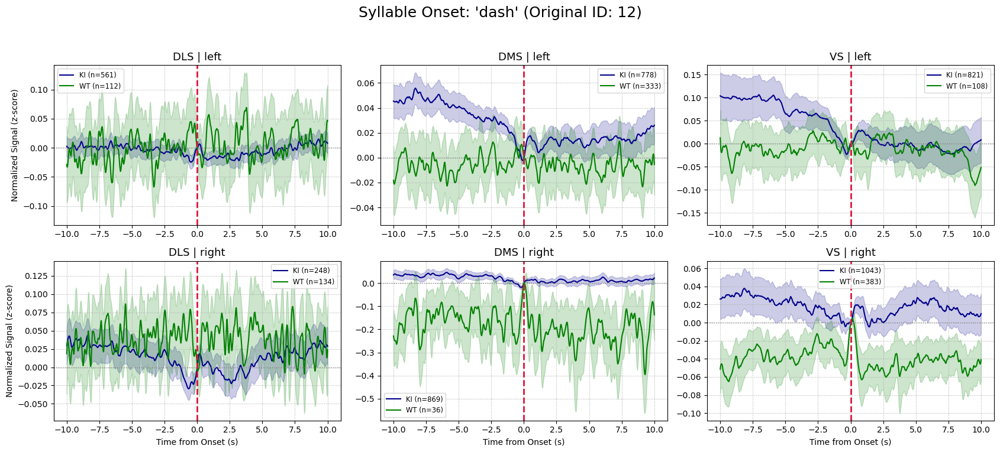

Skipped 13 KI traces for syllable 13.0, region VS, hemisphere left due to NaNs
Skipped 13 KI traces for syllable 13.0, region DMS, hemisphere right due to NaNs


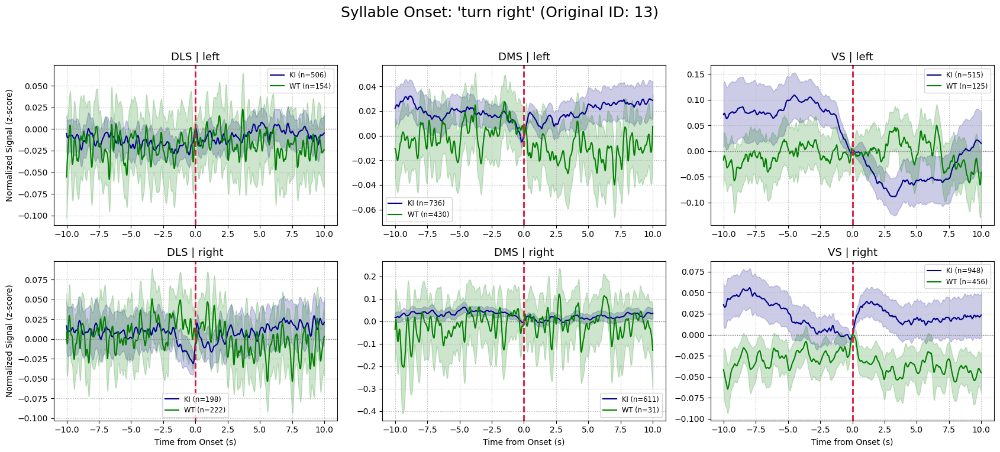

Skipped 8 KI traces for syllable 14.0, region VS, hemisphere left due to NaNs
Skipped 8 KI traces for syllable 14.0, region DMS, hemisphere right due to NaNs


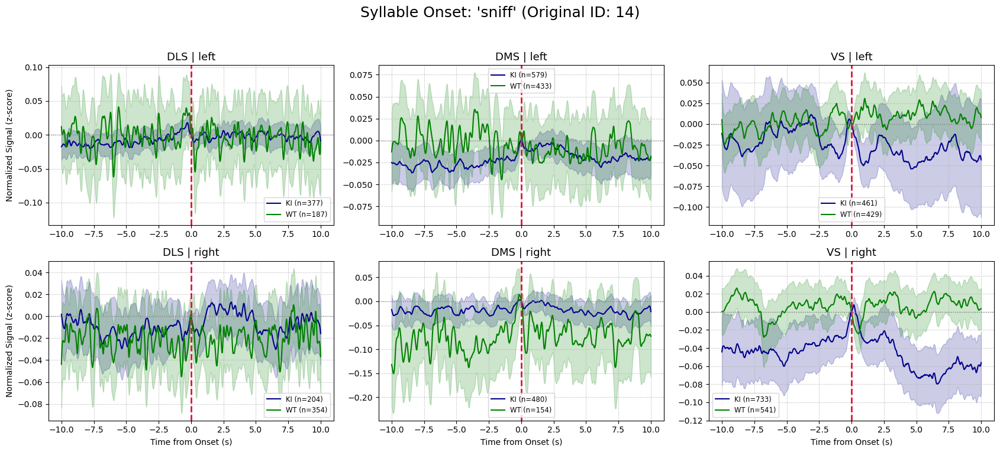

Skipped 10 KI traces for syllable 15.0, region VS, hemisphere left due to NaNs
Skipped 10 KI traces for syllable 15.0, region DMS, hemisphere right due to NaNs


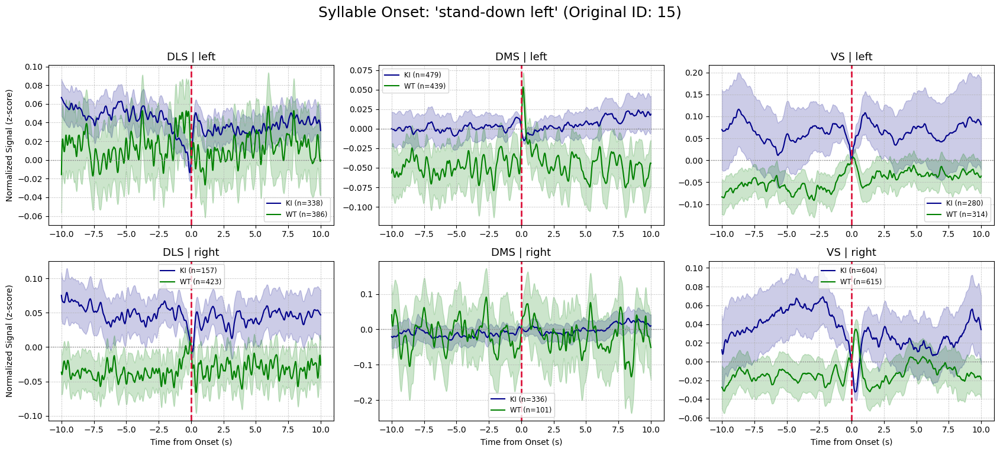

Skipped 11 KI traces for syllable 16.0, region VS, hemisphere left due to NaNs
Skipped 11 KI traces for syllable 16.0, region DMS, hemisphere right due to NaNs


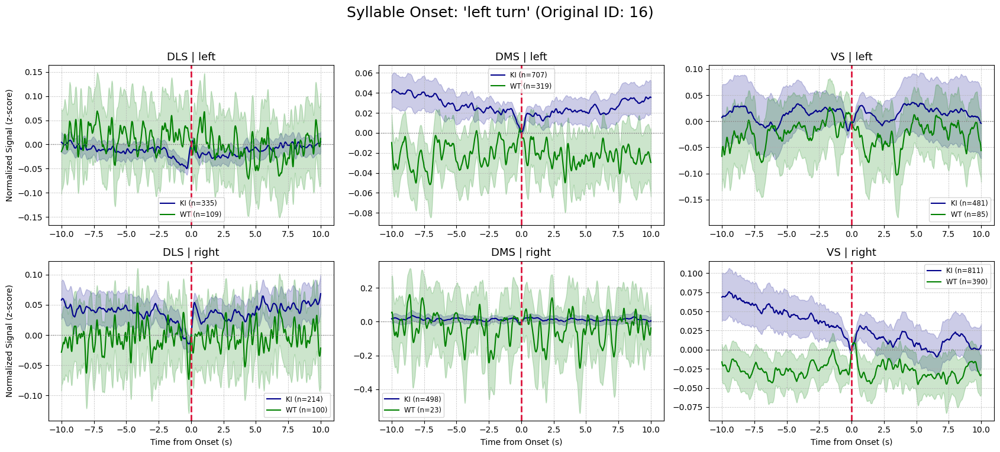

Skipped 12 KI traces for syllable 17.0, region VS, hemisphere left due to NaNs
Skipped 12 KI traces for syllable 17.0, region DMS, hemisphere right due to NaNs


KeyboardInterrupt: 

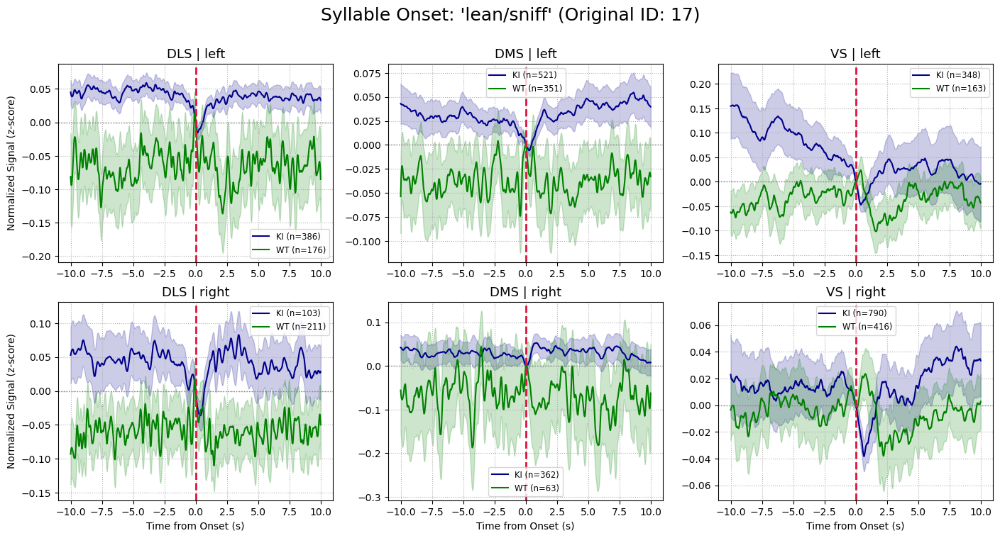

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import sem
from scipy.signal import savgol_filter

# --- Analysis & Smoothing Parameters ---
SAMPLING_RATE = 80
WINDOW_SECONDS = 10
SMOOTHING_WINDOW = 25
SMOOTHING_POLY_ORDER = 3
CONFIDENCE_LEVEL = 1.96
WINDOW_SAMPLES = int(WINDOW_SECONDS * SAMPLING_RATE)
TOTAL_SAMPLES = 2 * WINDOW_SAMPLES
SIGNAL_COLS = ['signal_0_470_dff_z', 'signal_1_470_dff_z']

# --- Syllable Label Setup (no reindexing) ---
LABEL_CSV_PATH = '/home/fsp585/Desktop/FiberphotometryCode/tests/kpms_all_sessions_frac_1_ld9_jn24/final_model_1.20e+06_idx1/syll_info.csv'
labels_df = pd.read_csv(LABEL_CSV_PATH)
labels_df['label'] = labels_df['label'].fillna('').str.strip()

# Map original syllable ID to label; fallback to "non-common" if missing/empty
syllable_id_to_label = {
    int(row.syllable): row.label if row.label else "non-common"
    for _, row in labels_df.iterrows()
}

# --- Data Processing Function ---
def process_session_data(session):
    """Processes a single session to extract, smooth, and baseline-correct traces."""
    df = session.dfs.data['synchronized_data_tracking_0']
    
    onsets = df[(df['syllable'].notna()) & (df['syllable'] != df['syllable'].shift(1))]
    
    syllable_traces = {s: {col: [] for col in SIGNAL_COLS} for s in onsets['syllable'].unique()}
    for index, row in onsets.iterrows():
        syllable = row['syllable']
        start_idx = index - WINDOW_SAMPLES
        end_idx = index + WINDOW_SAMPLES
        if start_idx >= 0 and end_idx <= len(df):
            for col in SIGNAL_COLS:
                trace = df.loc[start_idx:end_idx-1, col].values
                if len(trace) == TOTAL_SAMPLES:
                    syllable_traces[syllable][col].append(trace)

    processed_traces = {s: {col: [] for col in SIGNAL_COLS} for s in syllable_traces.keys()}
    for syllable, signals in syllable_traces.items():
        for signal_col, traces in signals.items():
            for trace in traces:
                trace_series = pd.Series(trace)
                interpolated = trace_series.interpolate(method='linear', limit_direction='both')
                smoothed = savgol_filter(interpolated, SMOOTHING_WINDOW, SMOOTHING_POLY_ORDER)
                baseline_value = smoothed[WINDOW_SAMPLES]
                normalized_trace = smoothed - baseline_value
                processed_traces[syllable][signal_col].append(normalized_trace)
                
    return processed_traces

# --- Analysis & Plotting ---

# 1. Process every session
processed_list = [process_session_data(s) for s in sessions]

# 2. Gather all syllables present across sessions
all_syllables = sorted({
    syll for proc in processed_list for syll in proc.keys()
})
print("Syllables to plot:", all_syllables)

# 3. Determine unique brain regions and hemispheres from sessions' metadata
regions = sorted({region for s in sessions for region, _, _ in s.brain_regions})
hemispheres = sorted({
    s.signal_meta["_".join(col.split("_")[:2])][1]
    for s in sessions
    for col in SIGNAL_COLS
    if "_".join(col.split("_")[:2]) in s.signal_meta
})
time_vector = np.linspace(-WINDOW_SECONDS, WINDOW_SECONDS, TOTAL_SAMPLES)

# 4. Plot each syllable with hemisphere rows (top=left, bottom=right) and region columns
for syl_idx, syllable in enumerate(all_syllables):
    final_label = syllable_id_to_label.get(int(syllable), f"Unknown ID: {syllable}")
    
    hemis_order = ['left', 'right']  # top row = left, bottom = right
    n_rows = 2
    n_cols = len(regions)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols + 2, 8))  # width scales with regions
    fig.suptitle(f"Syllable Onset: '{final_label}' (Original ID: {int(syllable)})", fontsize=18)

    time_vector = np.linspace(-WINDOW_SECONDS, WINDOW_SECONDS, TOTAL_SAMPLES)

    for row_idx, hemisphere in enumerate(hemis_order):
        for col_idx, region in enumerate(regions):
            ax = axes[row_idx, col_idx] if n_rows > 1 else axes[col_idx]
            traces_by_genotype = {'KI': [], 'WT': []}

            for s, proc_data in zip(sessions, processed_list):
                meta = s.signal_meta
                for col in SIGNAL_COLS:
                    prefix = "_".join(col.split("_")[:2])
                    if prefix not in meta:
                        continue
                    region_meta = meta[prefix][0]
                    hemi_meta = meta[prefix][1]
                    if region_meta == region and hemi_meta == hemisphere:
                        traces = proc_data.get(syllable, {}).get(col, [])
                        traces_by_genotype[s.genotype].extend(traces)

            for geno, traces in traces_by_genotype.items():
                if not traces:
                    continue
                valid_traces = [t for t in traces if not np.isnan(t).any()]
                n_skipped = len(traces) - len(valid_traces)
                if n_skipped > 0:
                    print(f"Skipped {n_skipped} {geno} traces for syllable {syllable}, region {region}, hemisphere {hemisphere} due to NaNs")
                if not valid_traces:
                    continue

                arr = np.stack(valid_traces)
                m = arr.mean(axis=0)
                e = sem(arr, axis=0)
                lower = m - CONFIDENCE_LEVEL * e
                upper = m + CONFIDENCE_LEVEL * e

                color = 'darkblue' if geno == 'KI' else 'green'
                ax.plot(time_vector, m, label=f"{geno} (n={len(traces)})", color=color)
                ax.fill_between(time_vector, lower, upper, color=color, alpha=0.2)

            ax.set_title(f"{region} | {hemisphere}", fontsize=13)
            ax.axvline(0, color='crimson', linestyle='--', lw=2)
            ax.axhline(0, color='grey', linestyle=':', lw=1)
            if row_idx == n_rows - 1:
                ax.set_xlabel("Time from Onset (s)")
            if col_idx == 0:
                ax.set_ylabel("Normalized Signal (z-score)")
            ax.grid(True, linestyle=':')
            ax.legend(fontsize='small')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    if syl_idx < 30:
        plt.savefig(f'syl_{syl_idx}.png')
    plt.show()


In [ ]:
kpms.plot_syll_stats_with_sem(
    stats_df,
    PROJECT_DIR,
    MODEL_NAME,
    plot_sig=True,  # whether to mark statistical significance with a star
    thresh=0.05,  # significance threshold
    stat="frequency",  # statistic to be plotted (e.g. 'duration' or 'velocity_px_s_mean')
    order="stat",  # order syllables by overall frequency ("stat") or degree of difference ("diff")
    ctrl_group="a",  # name of the control group for statistical testing
    exp_group="b",  # name of the experimental group for statistical testing
    figsize=(8, 4),  # figure size
    groups=stats_df["group"].unique(),  # groups to be plotted
);


In [ ]:
normalize = "bigram"  # normalization method ("bigram", "rows" or "columns")

trans_mats, usages, groups, syll_include = kpms.generate_transition_matrices(
    PROJECT_DIR,
    MODEL_NAME,
    normalize=normalize,
    min_frequency=0.010,  # minimum syllable frequency to include
)

kpms.visualize_transition_bigram(
    PROJECT_DIR,
    MODEL_NAME,
    groups,
    trans_mats,
    syll_include,
    normalize=normalize,
    show_syllable_names=True,  # label syllables by index (False) or index and name (True)
)


In [ ]:

kpms.plot_transition_graph_group(
    PROJECT_DIR,
    MODEL_NAME,
    groups,
    trans_mats,
    usages,
    syll_include,
    layout="circular",  # transition graph layout ("circular" or "spring")
    show_syllable_names=False,  # label syllables by index (False) or index and name (True)
)


In [ ]:
kpms.plot_transition_graph_group(
    PROJECT_DIR,
    MODEL_NAME,
    groups,
    trans_mats,
    usages,
    syll_include,
    layout="circular",  # transition graph layout ("circular" or "spring")
    show_syllable_names=True,  # label syllables by index (False) or index and name (True)
)


In [ ]:
kpms.plot_transition_graph_difference(
    PROJECT_DIR, MODEL_NAME, groups, trans_mats, usages, syll_include, layout="circular", show_syllable_names=True
)  # transition graph layout ("circular" or "spring")